CUSTOMER SEGMENTATION
Dataset Shape: (1000, 35)

Features used for segmentation:
['Age', 'Purchase_Amount', 'Frequency_of_Purchase', 'Brand_Loyalty', 'Product_Rating', 'Return_Rate', 'Customer_Satisfaction', 'Spending_per_Purchase_Frequency', 'Engagement_Score', 'Research_to_Decision_Ratio']

Features standardized successfully.


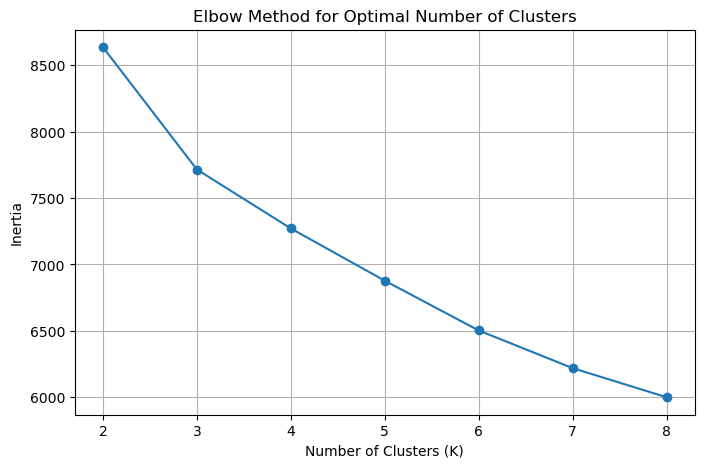


Silhouette Scores:
K = 2 → Silhouette Score = 0.1295
K = 3 → Silhouette Score = 0.1287
K = 4 → Silhouette Score = 0.1312
K = 5 → Silhouette Score = 0.1136
K = 6 → Silhouette Score = 0.1132
K = 7 → Silhouette Score = 0.1129
K = 8 → Silhouette Score = 0.1114

Best K based on Silhouette Score: 4

Customers in Each Segment:
Customer_Segment
0     63
1    361
2    361
3    215
Name: count, dtype: int64

Segment Characteristics:
                    Age  Purchase_Amount  Frequency_of_Purchase  \
Customer_Segment                                                  
0                 32.54           280.71                   6.81   
1                 34.50           236.92                   7.99   
2                 34.61           256.30                   7.90   
3                 33.99           368.96                   3.64   

                  Brand_Loyalty  Product_Rating  Return_Rate  \
Customer_Segment                                               
0                          3.25          

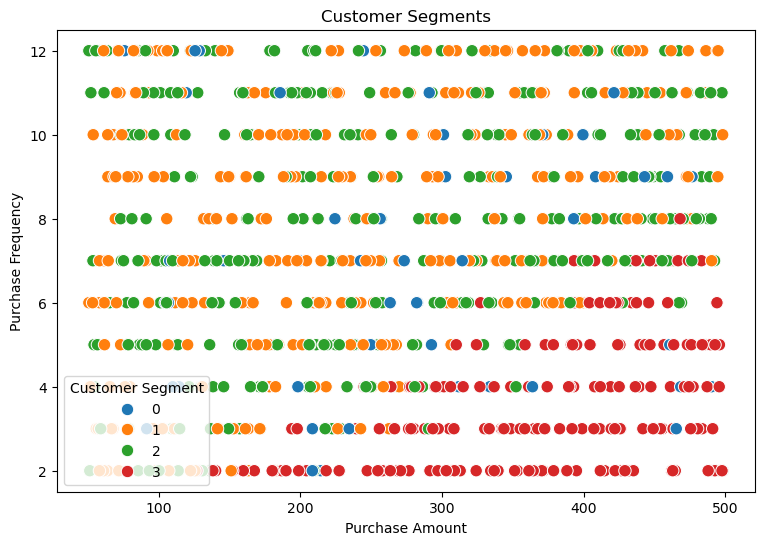

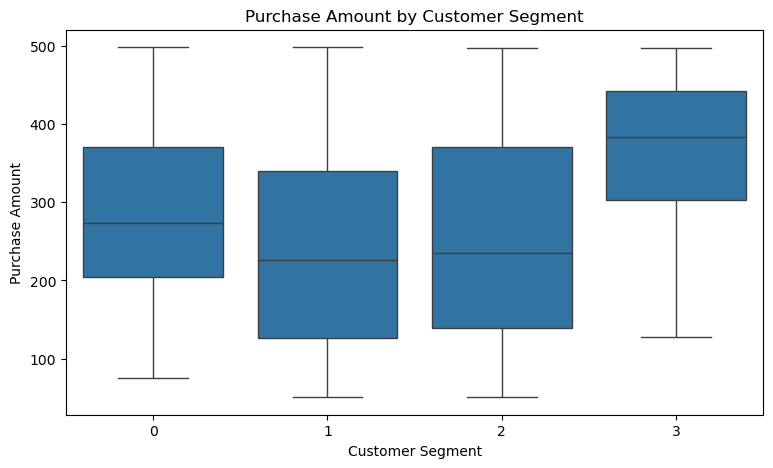


Segmented dataset saved successfully.
Segmentation model saved to: ../models/customer_segmentation.pkl

CUSTOMER SEGMENTATION COMPLETED


In [2]:
# ============================================================
# STEP 6: CUSTOMER SEGMENTATION USING K-MEANS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# 1. Load feature-engineered dataset
# ------------------------------------------------------------

df = pd.read_csv(
    "../data/processed/feature_engineered_data.csv"
)

print("=" * 60)
print("CUSTOMER SEGMENTATION")
print("=" * 60)

print("Dataset Shape:", df.shape)


# ------------------------------------------------------------
# 2. Select customer behavior features
# ------------------------------------------------------------

segmentation_features = [
    "Age",
    "Purchase_Amount",
    "Frequency_of_Purchase",
    "Brand_Loyalty",
    "Product_Rating",
    "Return_Rate",
    "Customer_Satisfaction",
    "Spending_per_Purchase_Frequency",
    "Engagement_Score",
    "Research_to_Decision_Ratio"
]

X = df[segmentation_features].copy()

print("\nFeatures used for segmentation:")
print(segmentation_features)


# ------------------------------------------------------------
# 3. Handle missing values
# ------------------------------------------------------------

X = X.fillna(X.median())


# ------------------------------------------------------------
# 4. Standardize features
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nFeatures standardized successfully.")


# ------------------------------------------------------------
# 5. Find suitable number of clusters using Elbow Method
# ------------------------------------------------------------

inertia = []

K_range = range(2, 9)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(K_range)
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 6. Silhouette Score
# ------------------------------------------------------------

silhouette_scores = {}

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores[k] = score


print("\nSilhouette Scores:")

for k, score in silhouette_scores.items():

    print(
        f"K = {k} → Silhouette Score = {score:.4f}"
    )


# ------------------------------------------------------------
# 7. Select K using highest silhouette score
# ------------------------------------------------------------

best_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print("\nBest K based on Silhouette Score:", best_k)


# ------------------------------------------------------------
# 8. Train final K-Means model
# ------------------------------------------------------------

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Customer_Segment"] = final_kmeans.fit_predict(
    X_scaled
)


# ------------------------------------------------------------
# 9. Display number of customers in each segment
# ------------------------------------------------------------

print("\nCustomers in Each Segment:")

print(
    df["Customer_Segment"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 10. Analyze each customer segment
# ------------------------------------------------------------

segment_summary = df.groupby(
    "Customer_Segment"
)[segmentation_features].mean().round(2)

print("\nSegment Characteristics:")
print(segment_summary)


# ------------------------------------------------------------
# 11. Visualize Customer Segments
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Purchase_Amount",
    y="Frequency_of_Purchase",
    hue="Customer_Segment",
    palette="tab10",
    s=80
)

plt.title("Customer Segments")
plt.xlabel("Purchase Amount")
plt.ylabel("Purchase Frequency")

plt.legend(
    title="Customer Segment"
)

plt.show()


# ------------------------------------------------------------
# 12. Segment spending visualization
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Customer_Segment",
    y="Purchase_Amount"
)

plt.title("Purchase Amount by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Purchase Amount")

plt.show()


# ------------------------------------------------------------
# 13. Save segmented dataset
# ------------------------------------------------------------

output_path = "../data/processed/feature_engineered_data.csv"

df.to_csv(
    output_path,
    index=False
)

print("\nSegmented dataset saved successfully.")


# ------------------------------------------------------------
# 14. Save K-Means model
# ------------------------------------------------------------

import joblib

model_path = "../models/customer_segmentation.pkl"

joblib.dump(
    {
        "model": final_kmeans,
        "scaler": scaler,
        "features": segmentation_features
    },
    model_path
)

print("Segmentation model saved to:", model_path)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CUSTOMER SEGMENTATION COMPLETED")
print("=" * 60)